# Knowledge Engineering: Autonomous (Self-Driving) Trailer Agent
**ICS 3202: Artificial Intelligence — Practical Exercise 4: Developing a Knowledge Based Agent**

| | |
|---|---|
| **Group** | 18 
| **Members** | Musyimi John Kioko (189983) · Kuria Jason Wainaina (189946) · Wangui Michelle Wachanga (176833) |

*Structure adapted from the Knowledge Engineering template (Smart Traffic Light Navigation Agent).*

**How this notebook is organised.** It follows the ten knowledge-engineering steps of the template. The agent is the **self-driving trailer from Exercise 3**, which must take cargo from **Nairobi to Kisumu**. One knowledge base (KB) answers two kinds of question:

1. **Where do I go?** — route planning over the Exercise 3 **directed graph**, using its **search tree** and **distance measures** (hops, road distance in km, and a straight-line heuristic).
2. **What do I do right now?** — driving decisions (traffic light, pedestrians, animals, weather, fuel, closed roads, emergency vehicles) made by **rules** that fire over **facts**.

**Step 1: Identify the Task**

The task is the one defined in Exercise 3: **move the trailer from Nairobi (initial state) to Kisumu (goal state)** over Kenya's highway network, where each action is a drive along one road to an adjacent town and the path cost is the total distance in km.

**Goal:** make safe driving decisions and reach Kisumu by the shortest *usable* route, with minimal risk to people, cargo and vehicle.

The agent must:
* plan a route over the directed road graph and re-plan when a road is closed;
* decide the correct driving action from what its sensors report;
* plan fuel stops so the trailer never runs dry between stations;
* explain *why* it chose an action (a KB should be able to justify its answers).

**Step 2: Assemble Relevant Knowledge**

The system needs to know the following. Most of it is carried over from **Practical Exercise 3**.

* **The directed road graph** (Exercise 3, Figure 1): 12 towns and the directed roads between them with their distances in km. Roads are directed because the two directions of one road can differ in length or be closed independently.
* **Search tree and measures** (Exercise 3, section 2): the search starts at Nairobi and the goal test is "current town is Kisumu". The path cost is C(P) = Σ d(vᵢ, vᵢ₊₁), and the best route is the path with the smallest cost (Dijkstra / uniform-cost search). Exercise 3's preliminary best candidate is Nairobi → Naivasha → Nakuru → Kericho → Kisumu = 91 + 71 + 106 + 89 = **357 km**.
* **PEAS** (Exercise 3, section 1.1), which tells us what knowledge the agent needs:

| | |
|---|---|
| Performance | short distance and time, no collisions, obey traffic laws, low fuel use, cargo delivered safely to Kisumu |
| Environment | Kenyan highways, towns, junctions, traffic, pedestrians, weather, road conditions (partially observable, stochastic, sequential, dynamic, hybrid) |
| Actuators | steering, accelerator, brakes, gear control, indicators, lights, horn |
| Sensors | GPS, cameras, radar, lidar, wheel-speed, odometry, engine sensors, digital maps, traffic information |

* **Straight-line geometry** — latitude/longitude of each town, used for the straight-line (haversine) distance that guides A* search.
* **Fuel** — where fuel is available and the trailer's range.
* **Road-safety knowledge** — what to do for each traffic-light state, obstacle, weather condition, load type and emergency, and which rule wins when two disagree. Safety always wins.

**Data note (important).** The road distances are the weights drawn in Exercise 3, Figure 1. Where the figure's arrows are unclear, the four route distances stated in Exercise 3 section 3.2 (91, 71, 106, 89 km) are used for the Nairobi→Kisumu direction. Exercise 3 itself says these distances still have to be checked against Google Maps. The check in Step 4 compares every weight with the straight-line distance and flags any road that is *shorter than the straight line*, which is physically impossible. The two worst offenders (Nairobi ↔ Kericho and Thika ↔ Nyeri) are replaced by independently sourced road distances (`USE_VERIFIED_DISTANCES = True`, the default); setting it to `False` restores Figure 1 exactly as drawn. The other two flagged roads (Kericho ↔ Kisii, Awendo ↔ Ahero) have no independent figure yet and are kept as drawn, and neither lies on the shortest route.

```
APIs / web scraping: none were used in this notebook, so there is no extra scraping code to upload.
Independent distance references used only for the data check: Rome2Rio (Nairobi–Kericho, Thika–Nyeri) and
distancecalculator.himmera.com (Ahero–Kisumu). Coordinates are approximate town-centre latitude/longitude.
```

**Step 3: Define the Vocabulary**

*Predicates* are represented in Python as **tuples** whose first element is the predicate name; *variables* start with `?` (for example `?city`).

| Predicate | Meaning | Kind |
|---|---|---|
| `Coord(city, lat, lon)` | location of a town | static fact |
| `Road(from, to, km)` | a **directed** road from one town to the next, with its length | static fact |
| `FuelStation(city)` | fuel is available in this town | static fact |
| `Load(type)` | what the trailer carries: `Heavy` or `Light` | static fact |
| `Closed(from, to)` | this directed road is closed (road works, flooding…) | learned fact |
| `Light(color)` | what the camera sees at a traffic light | sensor percept |
| `Obstacle(kind)` | `Pedestrian`, `Animal`, `Debris` | sensor percept |
| `Weather(kind)` | `Rain`, `Fog`, `Clear` | sensor percept |
| `EmergencyVehicle(state)` | `Approaching` | sensor percept |
| `Gradient(kind)` | `SteepDownhill` | sensor percept |
| `Fuel(level)` | `Low` when range left is below the warning level | sensor percept |
| `NextLeg(from, to)` | the next road on the planned route | agent state |
| `Required(action)` | an action the rules say is needed | **derived** (inferred) |

**Constants:**
* Light colours: `Red`, `Yellow`, `Green` (more are added in Step 5)
* Towns (Exercise 3, Figure 1): Nairobi, Thika, Nyeri, Embu, Naivasha, Nakuru, Kericho, Eldoret, Kisumu, Kisii, Awendo, Ahero
* Actions: `Stop`, `StopAndCheck`, `PullOver`, `PrepareToStop`, `BrakeEarly`, `EngineBrake`, `SlowDown`, `Proceed` (driving controls) and `Refuel`, `Reroute` (navigation advisories)

In [1]:
import math, heapq
from collections import deque
import matplotlib.pyplot as plt

class KnowledgeBase:
    """A small knowledge base: a set of facts (tuples) plus if-then rules, with forward chaining."""

    def __init__(self):
        self.facts = set()
        self.rules = []          # each rule: (name, [condition patterns], conclusion pattern)
        self.why = {}            # derived fact -> (rule name, supporting facts)

    # ---- telling the KB things ----
    def tell(self, *fact):
        self.facts.add(tuple(fact))

    def retract(self, *fact):
        self.facts.discard(tuple(fact))

    def retract_predicates(self, names):
        self.facts = {f for f in self.facts if f[0] not in names}
        self.why = {f: w for f, w in self.why.items() if f[0] not in names}

    def add_rule(self, name, conditions, conclusion):
        self.rules.append((name, [tuple(c) for c in conditions], tuple(conclusion)))

    # ---- matching (unification of patterns against ground facts) ----
    @staticmethod
    def _is_var(x):
        return isinstance(x, str) and x.startswith("?")

    def _match(self, pattern, fact, binding):
        if len(pattern) != len(fact):
            return None
        b = dict(binding)
        for p, f in zip(pattern, fact):
            if self._is_var(p):
                if p in b and b[p] != f:
                    return None
                b[p] = f
            elif p != f:
                return None
        return b

    def _solve(self, conditions, binding):
        if not conditions:
            yield binding, []
            return
        first, rest = conditions[0], conditions[1:]
        for fact in list(self.facts):
            b = self._match(first, fact, binding)
            if b is not None:
                for b2, support in self._solve(rest, b):
                    yield b2, [fact] + support

    # ---- asking the KB ----
    def ask(self, *pattern):
        """Return one binding dict per fact that matches the pattern."""
        return [b for b, _ in self._solve([tuple(pattern)], {})]

    def holds(self, *fact):
        return tuple(fact) in self.facts

    # ---- inference ----
    def forward_chain(self):
        """Apply every rule repeatedly until no new fact can be derived."""
        changed = True
        while changed:
            changed = False
            for name, conds, concl in self.rules:
                for b, support in list(self._solve(conds, {})):
                    new = tuple(b.get(x, x) if self._is_var(x) else x for x in concl)
                    if new not in self.facts:
                        self.facts.add(new)
                        self.why[new] = (name, support)
                        changed = True

    def explain(self, fact, indent=0):
        """Print the chain of reasoning that produced a derived fact."""
        fact = tuple(fact)
        pad = "   " * indent
        if fact in self.why:
            rule, support = self.why[fact]
            print(f"{pad}{fact}  <= by {rule}")
            for s in support:
                self.explain(s, indent + 1)
        else:
            print(f"{pad}{fact}  (observed / given)")

kb = KnowledgeBase()
print("Empty knowledge base created.")

Empty knowledge base created.


**Step 4: Encode General Knowledge about the Domain** `[3 marks]`

The vocabulary is declared in Step 3. Here the general knowledge is encoded in three parts: **(a)** the road network (directed graph + distances), **(b)** the trailer and fuel facts, and **(c)** the driving rules with their priorities.

**(a) Road network.** Each road is stored as **directed edges** `Road(a, b, km)`; most roads have a separate edge for each direction because a closure, a one-way diversion or road works can affect only one direction (and the two directions can have slightly different distances, as in Exercise 3, Figure 1).

In [2]:
# ---------------------------------------------------------------
# (a) Directed road graph from Practical Exercise 3 (Figure 1): (from, to) -> km
# ---------------------------------------------------------------
ROADS_AS_DRAWN = {
    ("Nairobi", "Naivasha"): 91,  ("Naivasha", "Nairobi"): 91,
    ("Naivasha", "Nakuru"): 71,   ("Nakuru", "Naivasha"): 73,
    ("Nakuru", "Kericho"): 106,   ("Kericho", "Nakuru"): 104,    # 106 and 89 are the Nairobi->Kisumu
    ("Kericho", "Kisumu"): 89,    ("Kisumu", "Kericho"): 91,     # values stated in Exercise 3, section 3.2
    ("Nakuru", "Eldoret"): 212,   ("Eldoret", "Nakuru"): 215,
    ("Kisumu", "Eldoret"): 168,   ("Eldoret", "Kisumu"): 170,
    ("Kericho", "Kisii"): 60,     ("Kisii", "Kericho"): 58,
    ("Kisii", "Awendo"): 47,      ("Awendo", "Kisii"): 50,
    ("Awendo", "Ahero"): 36,      ("Ahero", "Awendo"): 38,
    ("Nairobi", "Kericho"): 193,  ("Kericho", "Nairobi"): 193,
    ("Nairobi", "Thika"): 52,     ("Thika", "Nairobi"): 52,
    ("Thika", "Nyeri"): 56,       ("Nyeri", "Thika"): 56,
    ("Nyeri", "Embu"): 100,       ("Embu", "Nyeri"): 102,
}

# Independently sourced replacements for weights that fail the straight-line check below (see Step 9).
VERIFIED_FIXES = {
    ("Nairobi", "Kericho"): 261, ("Kericho", "Nairobi"): 261,   # Rome2Rio road distance ~260 km
    ("Thika", "Nyeri"): 106,     ("Nyeri", "Thika"): 106,       # Rome2Rio road distance ~106 km
}
USE_VERIFIED_DISTANCES = True      # True = replace the two impossible Exercise 3 weights with sourced ones; False = figure exactly as drawn

COORDS = {   # approximate town-centre (latitude, longitude)
    "Nairobi": (-1.29, 36.82), "Thika": (-1.04, 37.08), "Nyeri": (-0.43, 36.94), "Embu": (-0.54, 37.46),
    "Naivasha": (-0.72, 36.43), "Nakuru": (-0.30, 36.07), "Kericho": (-0.37, 35.28), "Eldoret": (0.51, 35.27),
    "Kisumu": (-0.09, 34.75), "Kisii": (-0.68, 34.77), "Awendo": (-0.90, 34.53), "Ahero": (-0.18, 34.92),
}
FUEL_STATIONS = ["Nairobi", "Thika", "Nyeri", "Embu", "Naivasha", "Nakuru", "Kericho", "Eldoret", "Kisumu", "Kisii"]
# (Awendo and Ahero have no fuel station in this KB)

roads = dict(ROADS_AS_DRAWN)
if USE_VERIFIED_DISTANCES:
    roads.update(VERIFIED_FIXES)

for city, (lat, lon) in COORDS.items():
    kb.tell("Coord", city, lat, lon)
for (a, b), km in roads.items():
    kb.tell("Road", a, b, km)          # one directed edge a -> b
for city in FUEL_STATIONS:
    kb.tell("FuelStation", city)

print(f"{len(kb.ask('Coord','?c','?lat','?lon'))} towns, "
      f"{len(kb.ask('Road','?a','?b','?km'))} directed roads, "
      f"{len(kb.ask('FuelStation','?c'))} fuel stations loaded "
      f"({'verified' if USE_VERIFIED_DISTANCES else 'as drawn in Exercise 3'} distances).")

def haversine(c1, c2):
    """Straight-line (great-circle) distance in km between two towns."""
    (la1, lo1), (la2, lo2) = COORDS[c1], COORDS[c2]
    p1, p2 = math.radians(la1), math.radians(la2)
    dphi, dlam = p2 - p1, math.radians(lo2 - lo1)
    h = math.sin(dphi/2)**2 + math.cos(p1)*math.cos(p2)*math.sin(dlam/2)**2
    return 2 * 6371 * math.asin(math.sqrt(h))

# DATA CHECK: a road can never be shorter than the straight line between its two towns.
def too_short(table):
    return sorted({tuple(sorted((a, b))) for (a, b), km in table.items() if km < haversine(a, b)})

print("\nExercise 3 Figure 1 as drawn - roads SHORTER than the straight-line distance (impossible for a real road):")
for a, b in too_short(ROADS_AS_DRAWN):
    print(f"   {a} <-> {b}: weights {ROADS_AS_DRAWN[(a, b)]} / {ROADS_AS_DRAWN[(b, a)]} km, straight line {haversine(a, b):.0f} km"
          + ("   -> replaced by a sourced value" if (a, b) in VERIFIED_FIXES and USE_VERIFIED_DISTANCES else ""))
left = too_short(roads)
print("Still flagged in the ACTIVE data:", [f"{a}-{b}" for a, b in left] or "none", "(re-measure on Google Maps)" if left else "")

12 towns, 26 directed roads, 10 fuel stations loaded (verified distances).

Exercise 3 Figure 1 as drawn - roads SHORTER than the straight-line distance (impossible for a real road):
   Ahero <-> Awendo: weights 38 / 36 km, straight line 91 km
   Kericho <-> Kisii: weights 60 / 58 km, straight line 66 km
   Kericho <-> Nairobi: weights 193 / 193 km, straight line 199 km   -> replaced by a sourced value
   Nyeri <-> Thika: weights 56 / 56 km, straight line 70 km   -> replaced by a sourced value
Still flagged in the ACTIVE data: ['Ahero-Awendo', 'Kericho-Kisii'] (re-measure on Google Maps)


In [3]:
# ---------------------------------------------------------------
# (b) Trailer facts and constants
# ---------------------------------------------------------------
kb.tell("Load", "Heavy")        # the trailer is carrying a heavy load
TANK_RANGE_KM   = 350           # distance on a full tank (a loaded trailer)
RESERVE_KM      = 40            # never plan to arrive with less than this left
LOW_FUEL_KM     = 100           # fuel warning level
SPEED_LIMIT     = 80            # km/h, assumed heavy-goods-vehicle limit

# ---------------------------------------------------------------
# (c) Driving rules  (IF all conditions THEN conclusion).  Variables start with '?'
# ---------------------------------------------------------------
kb.add_rule("R1  red light",        [("Light", "Red")],    ("Required", "Stop"))
kb.add_rule("R2  yellow light",     [("Light", "Yellow")], ("Required", "PrepareToStop"))
kb.add_rule("R3  green light",      [("Light", "Green")],  ("Required", "Proceed"))
kb.add_rule("R4  pedestrian",       [("Obstacle", "Pedestrian")], ("Required", "Stop"))
kb.add_rule("R5  animal on road",   [("Obstacle", "Animal")],     ("Required", "SlowDown"))
kb.add_rule("R6  debris on road",   [("Obstacle", "Debris")],     ("Required", "SlowDown"))
kb.add_rule("R7  rain",             [("Weather", "Rain")],        ("Required", "SlowDown"))
kb.add_rule("R8  fog",              [("Weather", "Fog")],         ("Required", "SlowDown"))
kb.add_rule("R9  emergency vehicle",[("EmergencyVehicle", "Approaching")], ("Required", "PullOver"))
kb.add_rule("R10 low fuel",         [("Fuel", "Low")],            ("Required", "Refuel"))
# rules that use TWO conditions (a join) or build on a derived fact (chaining):
kb.add_rule("R11 heavy load + stopping",  [("Load", "Heavy"), ("Required", "PrepareToStop")], ("Required", "BrakeEarly"))
kb.add_rule("R12 heavy load + downhill",  [("Load", "Heavy"), ("Gradient", "SteepDownhill")], ("Required", "EngineBrake"))
kb.add_rule("R13 next road is closed",    [("NextLeg", "?a", "?b"), ("Closed", "?a", "?b")],  ("Required", "Reroute"))

# Priorities decide between conflicting driving actions: the HIGHEST number wins (safety first).
PRIORITY = {"Stop": 100, "StopAndCheck": 95, "PullOver": 90, "BrakeEarly": 75, "PrepareToStop": 70,
            "EngineBrake": 65, "SlowDown": 60, "Proceed": 10}
NAVIGATION = {"Refuel", "Reroute"}          # advisories that never conflict with a driving control
SPEED_CAP = {"Stop": 0, "StopAndCheck": 0, "PullOver": 0, "BrakeEarly": 30, "PrepareToStop": 30,
             "EngineBrake": 40, "SlowDown": 40, "Proceed": SPEED_LIMIT}
MESSAGES = {
    "Stop": "Stop — it is unsafe to move.",
    "StopAndCheck": "Stop, check the junction, then proceed when it is clear.",
    "PullOver": "Pull over safely and let the emergency vehicle pass.",
    "BrakeEarly": "Begin braking early — the heavy trailer needs a longer stopping distance.",
    "PrepareToStop": "Slow down — prepare to stop.",
    "EngineBrake": "Use engine braking on the descent — the load is heavy.",
    "SlowDown": "Slow down and drive with caution.",
    "Proceed": "Go — it is safe to proceed.",
    "Refuel": "Refuel at the next fuel station.",
    "Reroute": "The next road is closed — re-plan the route.",
}

print(f"{len(kb.rules)} rules loaded.")

13 rules loaded.


**Search tree, directed graph and distance measures (from Practical Exercise 3).** (UCS is exactly the Dijkstra algorithm described in Exercise 3, section 2.4.) The planner below queries the KB for `Road` facts that are *not* `Closed`, and searches that directed graph with three strategies:

| Strategy | Measure it uses | Finds |
|---|---|---|
| **BFS** (breadth-first) | number of hops | the route with the *fewest towns*, not necessarily the shortest |
| **UCS** (uniform-cost) | road distance so far, `g(n)` | the *shortest* route in km |
| **A\*** | `g(n) + h(n)`, where `h(n)` is the (scaled) straight-line distance to the goal | the *shortest* route in km, usually exploring fewer towns |

Every node that gets generated is recorded, so the **search tree** can be printed.

In [4]:
def heuristic_factor():
    """Scale for the straight-line heuristic. Some Exercise 3 weights are shorter than the straight line,
    so we shrink the heuristic by the worst ratio: it then never over-estimates, and A* stays optimal."""
    ratios = [r["?km"] / haversine(r["?a"], r["?b"]) for r in kb.ask("Road", "?a", "?b", "?km")
              if haversine(r["?a"], r["?b"]) > 0]
    return min(1.0, min(ratios))

def usable_roads():
    """Directed adjacency {town: [(next town, km), ...]} from Road facts that are not Closed."""
    adj = {}
    for r in kb.ask("Road", "?a", "?b", "?km"):
        if not kb.holds("Closed", r["?a"], r["?b"]):
            adj.setdefault(r["?a"], []).append((r["?b"], r["?km"]))
    for town in adj:
        adj[town].sort()          # alphabetical order so results are repeatable
    return adj

def search(start, goal, strategy="astar"):
    """Graph search over the directed road graph. strategy: 'bfs', 'ucs' or 'astar'."""
    adj = usable_roads()
    nodes = [{"id": 0, "city": start, "parent": None, "g": 0, "hops": 0, "order": None, "note": ""}]
    counter = 0
    hf = heuristic_factor() if strategy == "astar" else 0
    def key(n):
        if strategy == "bfs":  return n["hops"]
        if strategy == "ucs":  return n["g"]
        return n["g"] + hf * haversine(n["city"], goal)
    frontier = [(key(nodes[0]), counter, 0)]
    explored, expanded = set(), 0
    while frontier:
        _, _, nid = heapq.heappop(frontier)
        node = nodes[nid]
        if node["city"] in explored:
            node["note"] = "discarded (town already reached)"
            continue
        explored.add(node["city"])
        expanded += 1
        node["order"] = expanded
        if node["city"] == goal:
            path, n = [], node
            while n is not None:
                path.append(n["city"]); n = nodes[n["parent"]] if n["parent"] is not None else None
            return {"path": path[::-1], "km": node["g"], "expanded": expanded, "nodes": nodes, "strategy": strategy}
        for nxt, km in adj.get(node["city"], []):
            if nxt in explored:
                continue
            child = {"id": len(nodes), "city": nxt, "parent": nid, "g": node["g"] + km,
                     "hops": node["hops"] + 1, "order": None, "note": ""}
            nodes.append(child)
            counter += 1
            heapq.heappush(frontier, (key(child), counter, child["id"]))
    return None     # no route exists

def print_tree(result, max_nodes=60):
    """Print the search tree: each line is a generated node  [expansion order, g = km so far]."""
    nodes = result["nodes"]
    children = {}
    for n in nodes:
        children.setdefault(n["parent"], []).append(n)
    shown = 0
    def walk(n, depth):
        nonlocal shown
        if shown >= max_nodes:
            return
        shown += 1
        tag = f"expanded #{n['order']}" if n["order"] else (n["note"] or "never expanded")
        print("   " * depth + f"{n['city']}  (g={n['g']} km, {tag})")
        for c in children.get(n["id"], []):
            walk(c, depth + 1)
    walk(nodes[0], 0)
    if shown >= max_nodes:
        print("   ... (tree truncated)")

def show_result(r, label):
    if r is None:
        print(f"{label}: no route available"); return
    print(f"{label}: {' -> '.join(r['path'])}\n     {r['km']} km, {len(r['path'])-1} hops, "
          f"{r['expanded']} towns expanded, about {r['km']/SPEED_LIMIT:.1f} h at {SPEED_LIMIT} km/h")

print("Planner ready.")

Planner ready.


**Step 5: Add New Facts to the Knowledge Base** `[4 marks]`

A knowledge-based agent must be able to **learn without being re-programmed**. We add four kinds of new knowledge: a **new road** that Exercise 3's graph is missing, new **fuel information**, new **rules** (traffic-light states the first version did not know), and a new **closure**. Facts and rules can be added directly from code, or typed in by a user through `add_fact_interactive()`.

The new road is **Ahero ↔ Kisumu (about 23 km)**. In Exercise 3, Figure 1, Ahero is connected only to Awendo, so the whole Kisii–Awendo–Ahero chain is a dead end that cannot reach Kisumu. Adding this one road gives the trailer a second way into Kisumu from the south.

In [5]:
def show_kb(predicate=None):
    """Print the KB, optionally only one predicate."""
    print("\n--- Current Knowledge Base ---")
    for f in sorted((f for f in kb.facts if predicate is None or f[0] == predicate), key=str):
        print("  ", f)
    print("------------------------------")

def add_new_fact(*fact):
    """Add a new fact directly to the KB (no user input)."""
    kb.tell(*fact)
    print("Added fact:", tuple(fact))

def add_road(a, b, km, two_way=True):
    """Add a directed road (and, by default, its reverse). Both towns must already have Coord facts."""
    assert a in COORDS and b in COORDS, "give both towns Coord facts first"
    add_new_fact("Road", a, b, km)
    if two_way:
        add_new_fact("Road", b, a, km)

def add_rule(name, conditions, conclusion):
    kb.add_rule(name, conditions, conclusion)
    print(f"Added rule {name}: IF {conditions} THEN {conclusion}")

# --- 1. a new road the Exercise 3 graph was missing (distancecalculator.himmera.com: about 23 km) ---
add_road("Ahero", "Kisumu", 23)

# --- 2. new fuel information ---
add_new_fact("FuelStation", "Awendo")

# --- 3. new light states the original rules did not cover ---
add_rule("R14 flashing light", [("Light", "Flashing")], ("Required", "StopAndCheck"))
add_rule("R15 dark signal",    [("Light", "Dark")],     ("Required", "StopAndCheck"))

# --- 4. a new closure: a landslide closes Embu -> Nyeri (one direction only) ---
add_new_fact("Closed", "Embu", "Nyeri")

# optional: let a user teach the agent a new road fact from the keyboard
def add_fact_interactive():
    a  = input("From town: ").strip().title()
    b  = input("To town:   ").strip().title()
    km = int(input("Distance in km: "))
    add_road(a, b, km, two_way=input("Two-way road? (y/n): ").lower().startswith("y"))
# add_fact_interactive()      # <- uncomment to type a new road in (both towns need Coord facts)

# the straight-line rule must still hold for the new road
assert 23 >= haversine("Ahero", "Kisumu"), "straight-line distance exceeds the road distance"
show_kb("Closed")
print()
print("Roads touching Ahero:", [(r['?a'], r['?b'], r['?km']) for r in kb.ask('Road', '?a', '?b', '?km') if 'Ahero' in (r['?a'], r['?b'])])

Added fact: ('Road', 'Ahero', 'Kisumu', 23)
Added fact: ('Road', 'Kisumu', 'Ahero', 23)
Added fact: ('FuelStation', 'Awendo')
Added rule R14 flashing light: IF [('Light', 'Flashing')] THEN ('Required', 'StopAndCheck')
Added rule R15 dark signal: IF [('Light', 'Dark')] THEN ('Required', 'StopAndCheck')
Added fact: ('Closed', 'Embu', 'Nyeri')

--- Current Knowledge Base ---
   ('Closed', 'Embu', 'Nyeri')
------------------------------

Roads touching Ahero: [('Kisumu', 'Ahero', 23), ('Ahero', 'Kisumu', 23), ('Ahero', 'Awendo', 38), ('Awendo', 'Ahero', 36)]


**Steps 6 & 7: Encode Specific Problem Instance (Facts) & Pose Queries and Get Answers** `[3 marks]`

**Step 6 — the problem instance.** A *problem instance* is one specific situation: the trailer sits in a town, its sensors report what they see, and it knows the next road on its route. The sensors are simulated, so each instance is written as a list of percept tuples. `perceive()` clears the previous moment's percepts, loads the new ones, and **normalises** them (colour names are capitalised and white-space trimmed).

**Step 7 — queries.** The agent asks the KB two kinds of question: *"what is the best route?"* and *"what should I do now?"*.

In [6]:
TRANSIENT = {"Light", "Obstacle", "Weather", "EmergencyVehicle", "Gradient", "Fuel", "NextLeg", "Required"}
KNOWN_LIGHTS = {"Red", "Yellow", "Green", "Flashing", "Dark"}

VALUES = {"Red", "Yellow", "Green", "Flashing", "Dark", "Pedestrian", "Animal", "Debris", "Rain", "Fog",
          "Clear", "Approaching", "SteepDownhill", "Low", "Heavy", "Light"} | set(COORDS)

def canon(value):
    """Match a sensor value to the KB's spelling, ignoring case and stray spaces ('  rEd ' -> 'Red')."""
    lookup = {v.lower(): v for v in VALUES}
    return lookup.get(value.strip().lower(), value.strip().capitalize())

def perceive(percepts):
    """Replace the previous percepts with new ones (Step 6: the current observation)."""
    kb.retract_predicates(TRANSIENT)
    for p in percepts:
        p = (p[0],) + tuple(canon(x) if isinstance(x, str) else x for x in p[1:])   # never touch the predicate name
        if p[0] == "Light":
            if p[1] in ("None", ""):          # no signal at this location: nothing to learn from it
                continue
            if p[1] not in KNOWN_LIGHTS:      # a colour the KB has no rule for
                p = ("Light", "Unknown")
        kb.tell(*p)

def decide():
    """Step 7: infer, then pick the highest-priority driving action plus any navigation advice."""
    kb.forward_chain()
    required = {f[1] for f in kb.facts if f[0] == "Required"}
    controls = [a for a in required if a in PRIORITY]
    advice   = sorted(a for a in required if a in NAVIGATION)
    unknown  = sorted(a for a in required if a not in PRIORITY and a not in NAVIGATION)
    primary  = max(controls, key=PRIORITY.get) if controls else "Proceed"
    return {"action": primary, "defaulted": not controls, "advice": advice,
            "speed": SPEED_CAP[primary], "others": sorted(set(controls) - {primary}), "unmapped": unknown}

def report(label, percepts):
    perceive(percepts)
    d = decide()
    print(f"{label}\n   sensors : {percepts if percepts else 'nothing unusual'}")
    print(f"   decision: {d['action']}  ->  {MESSAGES[d['action']]}" + ("  (default: no rule fired)" if d['defaulted'] else ""))
    print(f"   speed   : at most {d['speed']} km/h" + (f"   | also required: {d['others']}" if d['others'] else "")
          + (f"   | advice: {[MESSAGES[a] for a in d['advice']]}" if d['advice'] else ""))
    return d

print("=== Step 6: a specific problem instance ===")
report("Instance A — leaving Nairobi, load is heavy, the camera sees a red light",
       [("Light", "red")])

print("\n=== Step 7: pose queries ===")
r = search("Nairobi", "Kisumu", "astar")
show_result(r, "Query: best route Nairobi -> Kisumu (A*)")

=== Step 6: a specific problem instance ===
Instance A — leaving Nairobi, load is heavy, the camera sees a red light
   sensors : [('Light', 'red')]
   decision: Stop  ->  Stop — it is unsafe to move.
   speed   : at most 0 km/h

=== Step 7: pose queries ===
Query: best route Nairobi -> Kisumu (A*): Nairobi -> Kericho -> Kisumu
     350 km, 2 hops, 8 towns expanded, about 4.4 h at 80 km/h


**Step 8: Querying the knowledge base**

Asking questions to get actions and answers from known facts. First the **driving** queries, then **route and distance** queries, and finally the three search strategies side by side, with the search tree printed for one of them.

In [7]:
print("--- Driving queries ---")
report("Q1: light is Green, nothing else", [("Light", "Green")])
report("Q2: light Yellow while carrying a heavy load  (needs a CHAINED rule R2 -> R11)", [("Light", "Yellow")])
report("Q3: light Green BUT a pedestrian is crossing  (conflict: safety wins)", [("Light", "Green"), ("Obstacle", "Pedestrian")])
report("Q4: rain and an animal on the road", [("Weather", "Rain"), ("Obstacle", "Animal")])
report("Q5: emergency vehicle approaching from behind", [("EmergencyVehicle", "Approaching")])
report("Q6: steep downhill with the heavy load", [("Gradient", "SteepDownhill")])
report("Q7: flashing signal  (rule added in Step 5)", [("Light", "Flashing")])
report("Q8: low fuel on an otherwise clear road", [("Fuel", "Low")])

print("\nWhy did Q2 end in BrakeEarly? Ask the KB to explain:")
perceive([("Light", "Yellow")]); decide()
kb.explain(("Required", "BrakeEarly"))

--- Driving queries ---
Q1: light is Green, nothing else
   sensors : [('Light', 'Green')]
   decision: Proceed  ->  Go — it is safe to proceed.
   speed   : at most 80 km/h
Q2: light Yellow while carrying a heavy load  (needs a CHAINED rule R2 -> R11)
   sensors : [('Light', 'Yellow')]
   decision: BrakeEarly  ->  Begin braking early — the heavy trailer needs a longer stopping distance.
   speed   : at most 30 km/h   | also required: ['PrepareToStop']
Q3: light Green BUT a pedestrian is crossing  (conflict: safety wins)
   sensors : [('Light', 'Green'), ('Obstacle', 'Pedestrian')]
   decision: Stop  ->  Stop — it is unsafe to move.
   speed   : at most 0 km/h   | also required: ['Proceed']
Q4: rain and an animal on the road
   sensors : [('Weather', 'Rain'), ('Obstacle', 'Animal')]
   decision: SlowDown  ->  Slow down and drive with caution.
   speed   : at most 40 km/h
Q5: emergency vehicle approaching from behind
   sensors : [('EmergencyVehicle', 'Approaching')]
   decision: PullOv

In [8]:
print("--- Route and distance queries ---")
print("Neighbours of Nairobi:", [(r['?b'], r['?km']) for r in kb.ask('Road', 'Nairobi', '?b', '?km')])
print("Towns with fuel     :", sorted(r['?c'] for r in kb.ask('FuelStation', '?c')))
print("Closed roads        :", [(r['?a'], r['?b']) for r in kb.ask('Closed', '?a', '?b')])
print("Straight-line Nairobi -> Kisumu: %.0f km (a lower bound; the road is longer)" % haversine("Nairobi", "Kisumu"))
print("Heuristic scale factor used by A*: %.2f\n" % heuristic_factor())

for strat, name in [("bfs", "BFS  (fewest hops)"), ("ucs", "UCS  (shortest km)"), ("astar", "A*   (shortest km + heuristic)")]:
    show_result(search("Nairobi", "Kisumu", strat), name)

print("\n--- Search tree for UCS (Dijkstra) from Nairobi to Kisumu ---")
print_tree(search("Nairobi", "Kisumu", "ucs"))

--- Route and distance queries ---
Neighbours of Nairobi: [('Naivasha', 91), ('Thika', 52), ('Kericho', 261)]
Towns with fuel     : ['Awendo', 'Eldoret', 'Embu', 'Kericho', 'Kisii', 'Kisumu', 'Nairobi', 'Naivasha', 'Nakuru', 'Nyeri', 'Thika']
Closed roads        : [('Embu', 'Nyeri')]
Straight-line Nairobi -> Kisumu: 266 km (a lower bound; the road is longer)
Heuristic scale factor used by A*: 0.40

BFS  (fewest hops): Nairobi -> Kericho -> Kisumu
     350 km, 2 hops, 6 towns expanded, about 4.4 h at 80 km/h
UCS  (shortest km): Nairobi -> Kericho -> Kisumu
     350 km, 2 hops, 9 towns expanded, about 4.4 h at 80 km/h
A*   (shortest km + heuristic): Nairobi -> Kericho -> Kisumu
     350 km, 2 hops, 8 towns expanded, about 4.4 h at 80 km/h

--- Search tree for UCS (Dijkstra) from Nairobi to Kisumu ---
Nairobi  (g=0 km, expanded #1)
   Kericho  (g=261 km, expanded #7)
      Kisii  (g=321 km, expanded #8)
         Awendo  (g=368 km, never expanded)
      Kisumu  (g=350 km, expanded #9)
   N

**Dijkstra step by step** (the algorithm from Exercise 3, section 2.4): start with Nairobi at cost 0, repeatedly select the unvisited town with the smallest known cost, update its neighbours, and stop when Kisumu is selected.

In [9]:
def dijkstra_trace(start, goal):
    adj = usable_roads()
    dist = {t: math.inf for t in COORDS}; dist[start] = 0
    prev, done, step = {}, [], 0
    print(f"{'step':<5}{'selected':<10}{'cost':>6}   cost updates to neighbours")
    while True:
        open_towns = [t for t in dist if t not in done and dist[t] < math.inf]
        if not open_towns:
            print("goal unreachable"); return None
        u = min(open_towns, key=lambda t: (dist[t], t))
        done.append(u); step += 1
        updates = []
        for v, km in adj.get(u, []):
            if v not in done and dist[u] + km < dist[v]:
                dist[v] = dist[u] + km; prev[v] = u; updates.append(f"{v}={dist[v]}")
        print(f"{step:<5}{u:<10}{dist[u]:>6}   {', '.join(updates) or '-'}")
        if u == goal:
            break
    path, t = [goal], goal
    while t != start:
        t = prev[t]; path.append(t)
    return path[::-1], dist[goal]

path, cost = dijkstra_trace("Nairobi", "Kisumu")
print("\nDijkstra result:", " -> ".join(path), f"= {cost} km")

step selected    cost   cost updates to neighbours
1    Nairobi        0   Kericho=261, Naivasha=91, Thika=52
2    Thika         52   Nyeri=158
3    Naivasha      91   Nakuru=162
4    Nyeri        158   Embu=258
5    Nakuru       162   Eldoret=374
6    Embu         258   -
7    Kericho      261   Kisii=321, Kisumu=350
8    Kisii        321   Awendo=368
9    Kisumu       350   Ahero=373

Dijkstra result: Nairobi -> Kericho -> Kisumu = 350 km


**Comparing alternative paths** (Exercise 3, section 3.3). The agent compares the total cost of every candidate instead of assuming the route with the fewest towns is the shortest. `path_cost` returns `None` when a candidate uses a road that does not exist in the graph.

In [10]:
def path_cost(path):
    total = 0
    for a, b in zip(path, path[1:]):
        km = [r["?km"] for r in kb.ask("Road", a, b, "?km") if not kb.holds("Closed", a, b)]
        if not km:
            return None                  # no such (open) road
        total += km[0]
    return total

candidates = {
    "A  Nairobi-Naivasha-Nakuru-Kericho-Kisumu (Exercise 3 candidate A)": ["Nairobi", "Naivasha", "Nakuru", "Kericho", "Kisumu"],
    "B  Nairobi-Nakuru-Kericho-Kisumu (Exercise 3 candidate B)":          ["Nairobi", "Nakuru", "Kericho", "Kisumu"],
    "C  Nairobi-Naivasha-Nakuru-Eldoret-Kisumu (Exercise 3 candidate C)": ["Nairobi", "Naivasha", "Nakuru", "Eldoret", "Kisumu"],
    "D  Nairobi-Kericho-Kisumu (uses the direct Nairobi-Kericho edge)":   ["Nairobi", "Kericho", "Kisumu"],
    "E  Nairobi-Thika-Nyeri-Embu-... (Thika corridor)":                   ["Nairobi", "Thika", "Nyeri", "Embu", "Kisumu"],
}
print("Candidate routes Nairobi -> Kisumu")
for name, p in candidates.items():
    c = path_cost(p)
    print(f"  {name}\n      cost: {str(c) + ' km' if c is not None else 'INVALID - a road in this path does not exist in the graph'}")

def all_paths(start, goal):
    adj = usable_roads(); found = []
    def dfs(town, path, km):
        if town == goal:
            found.append((km, list(path))); return
        for nxt, w in adj.get(town, []):
            if nxt not in path:
                path.append(nxt); dfs(nxt, path, km + w); path.pop()
    dfs(start, [start], 0)
    return sorted(found)

routes = all_paths("Nairobi", "Kisumu")
print(f"\nAll {len(routes)} loop-free routes Nairobi -> Kisumu, cheapest first (top 6):")
for km, p in routes[:6]:
    print(f"  {km:4d} km  {' -> '.join(p)}")
print("\nThe Thika corridor (Thika-Nyeri-Embu) never reaches Kisumu in the graph: it is a dead end.")

# cross-check: A* and UCS must give the same distance for every pair of towns
towns = sorted(COORDS)
mismatch = [(a, b) for a in towns for b in towns if a != b
            and (search(a, b, "ucs") or {}).get("km") != (search(a, b, "astar") or {}).get("km")]
print("\nA* vs UCS agree on all", len(towns)*(len(towns)-1), "town pairs:", "YES" if not mismatch else mismatch)

Candidate routes Nairobi -> Kisumu
  A  Nairobi-Naivasha-Nakuru-Kericho-Kisumu (Exercise 3 candidate A)
      cost: 357 km
  B  Nairobi-Nakuru-Kericho-Kisumu (Exercise 3 candidate B)
      cost: INVALID - a road in this path does not exist in the graph
  C  Nairobi-Naivasha-Nakuru-Eldoret-Kisumu (Exercise 3 candidate C)
      cost: 544 km
  D  Nairobi-Kericho-Kisumu (uses the direct Nairobi-Kericho edge)
      cost: 350 km
  E  Nairobi-Thika-Nyeri-Embu-... (Thika corridor)
      cost: INVALID - a road in this path does not exist in the graph

All 6 loop-free routes Nairobi -> Kisumu, cheapest first (top 6):
   350 km  Nairobi -> Kericho -> Kisumu
   357 km  Nairobi -> Naivasha -> Nakuru -> Kericho -> Kisumu
   427 km  Nairobi -> Kericho -> Kisii -> Awendo -> Ahero -> Kisumu
   434 km  Nairobi -> Naivasha -> Nakuru -> Kericho -> Kisii -> Awendo -> Ahero -> Kisumu
   544 km  Nairobi -> Naivasha -> Nakuru -> Eldoret -> Kisumu
   747 km  Nairobi -> Kericho -> Nakuru -> Eldoret -> Kisumu

T

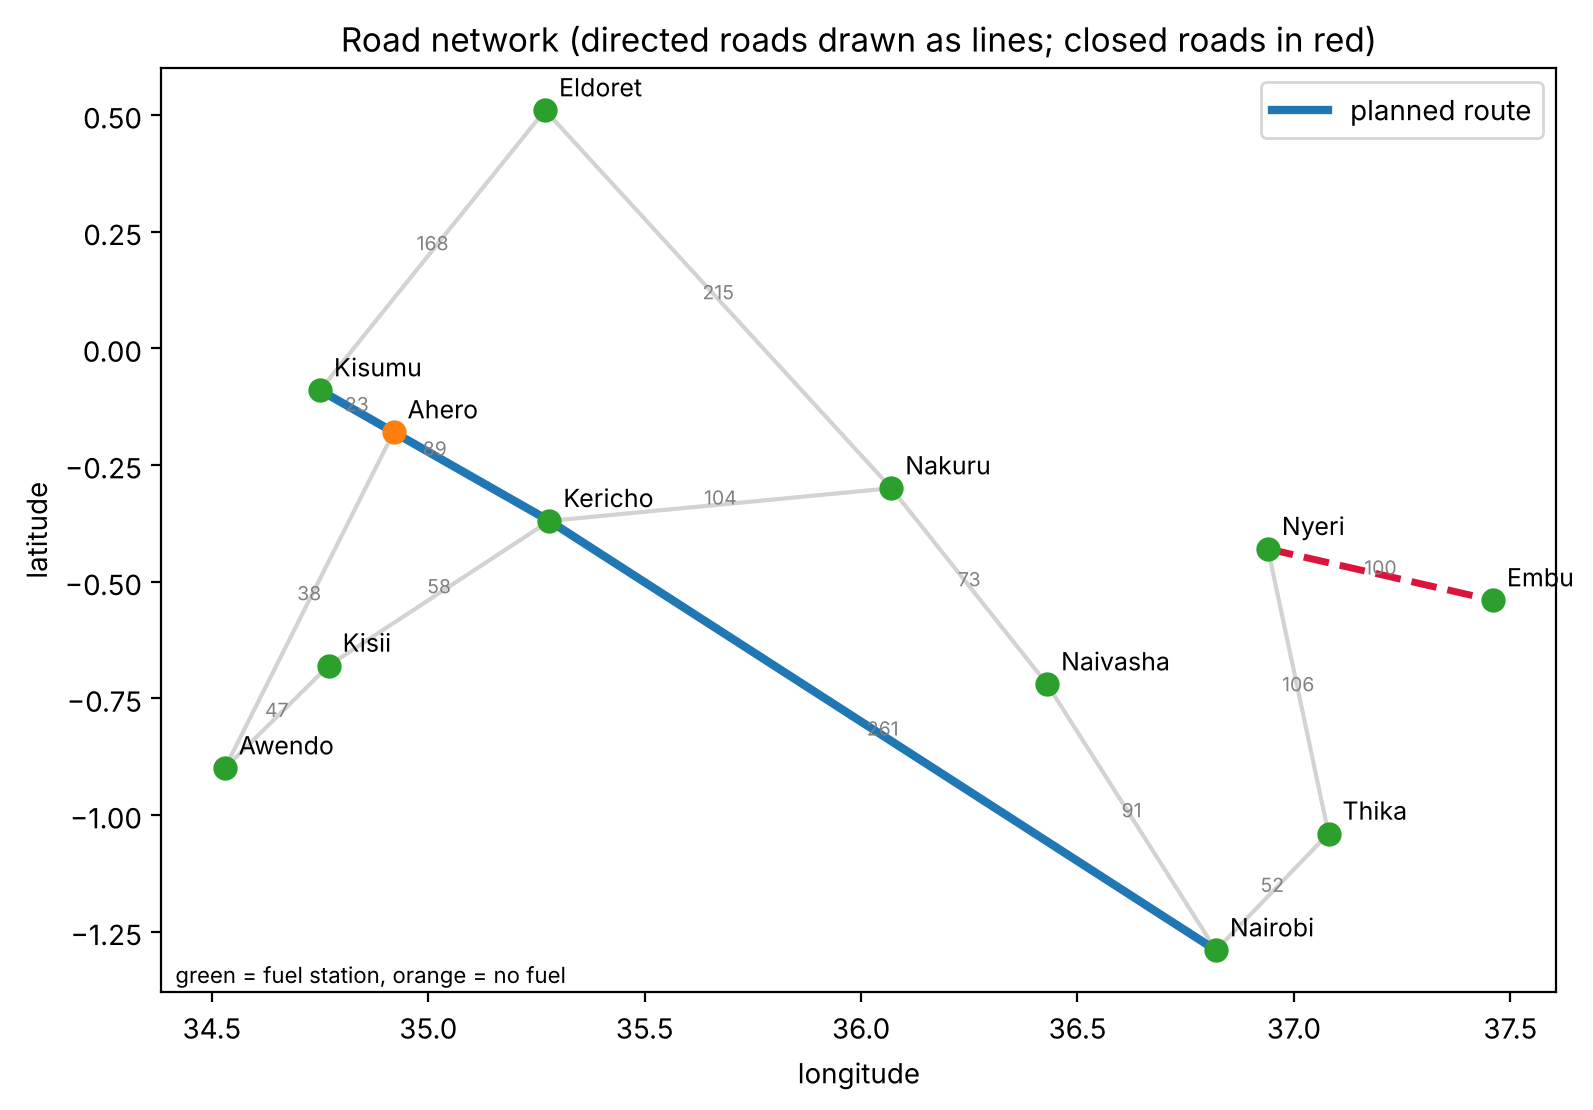

In [11]:
def plot_network(route=None, title="Road network (directed roads drawn as lines; closed roads in red)"):
    fig, ax = plt.subplots(figsize=(9, 6))
    seen = set()
    for r in kb.ask("Road", "?a", "?b", "?km"):
        a, b = r["?a"], r["?b"]
        if (b, a) in seen: continue
        seen.add((a, b))
        closed = kb.holds("Closed", a, b) or kb.holds("Closed", b, a)
        (la1, lo1), (la2, lo2) = COORDS[a], COORDS[b]
        ax.plot([lo1, lo2], [la1, la2], color="crimson" if closed else "lightgray",
                lw=2.5 if closed else 1.5, ls="--" if closed else "-", zorder=1)
        ax.text((lo1+lo2)/2, (la1+la2)/2, str(r["?km"]), fontsize=7, color="gray", ha="center")
    if route:
        xs = [COORDS[c][1] for c in route]; ys = [COORDS[c][0] for c in route]
        ax.plot(xs, ys, color="tab:blue", lw=3, zorder=2, label="planned route")
        ax.legend()
    for c, (la, lo) in COORDS.items():
        ax.scatter(lo, la, s=60, zorder=3, color="tab:green" if kb.holds("FuelStation", c) else "tab:orange")
        ax.annotate(c, (lo, la), textcoords="offset points", xytext=(5, 5), fontsize=9)
    ax.set_title(title); ax.set_xlabel("longitude"); ax.set_ylabel("latitude")
    ax.text(0.01, 0.01, "green = fuel station, orange = no fuel", transform=ax.transAxes, fontsize=8)
    plt.show()

plot_network(search("Nairobi", "Kisumu", "astar")["path"])

**The agent loop: drive a whole trip.** This ties the two halves together. At every town the trailer (1) perceives, (2) asks the KB what to do, (3) re-plans if the KB says the next road is closed, (4) refuels when the fuel plan or a fuel warning says so, and (5) drives to the next town. The fuel plan looks ahead: at a fuel station it refuels if it could not otherwise reach the *next* station (or the destination) with the reserve left. The plan printed at the start is a forecast; the live agent re-checks at every station and also refuels when the low-fuel warning (`Fuel(Low)`) fires, so the actual stops can differ slightly from the forecast.

The sensor readings along the way are **scripted**, so the run is repeatable and can be marked.

In [12]:
def road_km(a, b):
    return next(r["?km"] for r in kb.ask("Road", a, b, "?km"))

def km_to_next_station(route, i):
    """Distance from route[i] to the next fuel station (or the destination) further along the route."""
    d, j = 0, i
    while j < len(route) - 1:
        d += road_km(route[j], route[j+1]); j += 1
        if kb.holds("FuelStation", route[j]) or j == len(route) - 1:
            break
    return d

def needs_refuel_here(route, i, left):
    """Refuel at route[i] if it is a station and we could not otherwise reach the next one with the reserve."""
    return kb.holds("FuelStation", route[i]) and left - km_to_next_station(route, i) < RESERVE_KM

def plan_fuel_stops(route, range_left):
    """Return (set of towns to refuel at, feasible?) for this route, starting with range_left km."""
    stops, left, feasible = set(), range_left, True
    for i in range(len(route) - 1):
        if needs_refuel_here(route, i, left):
            stops.add(route[i]); left = TANK_RANGE_KM
        if left - km_to_next_station(route, i) < RESERVE_KM:
            feasible = False            # cannot reach the next station/destination with the reserve left
        left -= road_km(route[i], route[i+1])
    return stops, feasible

def drive(origin, destination, scenario, strategy="astar"):
    """Simulate a trip. scenario = {town: {'percepts': [...], 'learn': [...]}}"""
    result = search(origin, destination, strategy)
    if result is None:
        print("No route exists."); return
    route, pos, left, trip_km = result["path"], origin, TANK_RANGE_KM, 0
    print(f"Planned route: {' -> '.join(route)}  ({result['km']} km)")
    stops, ok = plan_fuel_stops(route, left)
    print(f"Fuel plan    : expect to refuel at {sorted(stops) or 'nowhere'}  (feasible: {ok})\n")
    while True:
        info = scenario.get(pos, {})
        for fact in info.get("learn", []):
            kb.tell(*fact); print(f"[{pos}] learned new fact: {fact}")
        percepts = list(info.get("percepts", []))
        if left <= LOW_FUEL_KM:
            percepts.append(("Fuel", "Low"))
        if pos == destination:
            print(f"[{pos}] ARRIVED. Trip distance {trip_km} km, range left {left} km."); return
        nxt = route[route.index(pos) + 1]
        perceive(percepts + [("NextLeg", pos, nxt)])
        d = decide()
        if "Reroute" in d["advice"]:
            new = search(pos, destination, strategy)
            if new is None:
                print(f"[{pos}] road to {nxt} closed and NO alternative route — stopping here."); return
            route = new["path"]; nxt = route[1]
            print(f"[{pos}] REROUTE -> {' -> '.join(route)}  ({new['km']} km from here)")
            stops, ok = plan_fuel_stops(route, left)
            print(f"        new fuel plan: {sorted(stops) or 'no stop needed'} (feasible: {ok})")
            perceive(percepts + [("NextLeg", pos, nxt)]); d = decide()
        refuel = kb.holds("FuelStation", pos) and (needs_refuel_here(route, route.index(pos), left) or "Refuel" in d["advice"])
        note = f"  + {', '.join(d['others'])}" if d["others"] else ""
        print(f"[{pos}] sensors={percepts or 'clear'} -> {d['action']} (<= {d['speed']} km/h){note}"
              + ("  [REFUEL]" if refuel else "") + ("  [fuel low: refuel at next station]" if "Refuel" in d['advice'] and not refuel else ""))
        if refuel:
            left = TANK_RANGE_KM
        leg = road_km(pos, nxt)
        left -= leg; trip_km += leg; pos = nxt
        assert left >= 0, "ran out of fuel!"

In [13]:
import copy

def run_trip(title, origin, destination, scenario, closed_at_start=(), strategy="astar"):
    """Run one trip on a copy of the KB state, then restore the KB so runs do not affect each other."""
    snapshot = (set(kb.facts), dict(kb.why))
    for c in closed_at_start:
        kb.tell("Closed", *c)
    print("=" * 78); print(title); print("=" * 78)
    drive(origin, destination, scenario, strategy)
    kb.facts, kb.why = snapshot[0], snapshot[1]
    print()

# Scripted sensor readings: what the trailer sees when it reaches each town.
scenario = {
    "Nairobi":  {"percepts": [("Light", "Yellow")]},
    "Naivasha": {"percepts": [("Weather", "Fog"), ("Gradient", "SteepDownhill")]},
    "Nakuru":   {"percepts": [("Light", "Red"), ("Obstacle", "Pedestrian")]},
    "Kericho":  {"percepts": [("Weather", "Rain"), ("Obstacle", "Animal")]},
    "Kisii":    {"percepts": [("Light", "Green")]},
}

run_trip("Run 1: Nairobi -> Kisumu, no closures (the plan comes straight from the KB)", "Nairobi", "Kisumu", scenario)

Run 1: Nairobi -> Kisumu, no closures (the plan comes straight from the KB)
Planned route: Nairobi -> Kericho -> Kisumu  (350 km)
Fuel plan    : expect to refuel at ['Kericho']  (feasible: True)

[Nairobi] sensors=[('Light', 'Yellow')] -> BrakeEarly (<= 30 km/h)  + PrepareToStop
[Kericho] sensors=[('Weather', 'Rain'), ('Obstacle', 'Animal'), ('Fuel', 'Low')] -> SlowDown (<= 40 km/h)  [REFUEL]
[Kisumu] ARRIVED. Trip distance 350 km, range left 261 km.



In [14]:
# Run 2: the agent learns on leaving Nairobi that the direct Nairobi -> Kericho road is closed.
scenario2 = copy.deepcopy(scenario)
scenario2["Nairobi"]["learn"] = [("Closed", "Nairobi", "Kericho")]      # discovered on the spot
run_trip("Run 2: the direct Nairobi -> Kericho road turns out to be closed", "Nairobi", "Kisumu", scenario2)

Run 2: the direct Nairobi -> Kericho road turns out to be closed
Planned route: Nairobi -> Kericho -> Kisumu  (350 km)
Fuel plan    : expect to refuel at ['Kericho']  (feasible: True)

[Nairobi] learned new fact: ('Closed', 'Nairobi', 'Kericho')
[Nairobi] REROUTE -> Nairobi -> Naivasha -> Nakuru -> Kericho -> Kisumu  (357 km from here)
        new fuel plan: ['Kericho'] (feasible: True)
[Nairobi] sensors=[('Light', 'Yellow')] -> BrakeEarly (<= 30 km/h)  + PrepareToStop
[Naivasha] sensors=[('Weather', 'Fog'), ('Gradient', 'SteepDownhill')] -> EngineBrake (<= 40 km/h)  + SlowDown
[Nakuru] sensors=[('Light', 'Red'), ('Obstacle', 'Pedestrian')] -> Stop (<= 0 km/h)
[Kericho] sensors=[('Weather', 'Rain'), ('Obstacle', 'Animal'), ('Fuel', 'Low')] -> SlowDown (<= 40 km/h)  [REFUEL]
[Kisumu] ARRIVED. Trip distance 357 km, range left 261 km.



In [15]:
# Run 3: the trailer reaches Kericho and learns that Kericho -> Kisumu is closed.
# The road added in Step 5 (Ahero -> Kisumu) now gives it a way in through Kisii, Awendo and Ahero.
scenario3 = copy.deepcopy(scenario)
scenario3["Kericho"]["learn"] = [("Closed", "Kericho", "Kisumu")]
run_trip("Run 3: the Kericho -> Kisumu road is closed (discovered on arrival at Kericho)", "Nairobi", "Kisumu", scenario3)

Run 3: the Kericho -> Kisumu road is closed (discovered on arrival at Kericho)
Planned route: Nairobi -> Kericho -> Kisumu  (350 km)
Fuel plan    : expect to refuel at ['Kericho']  (feasible: True)

[Nairobi] sensors=[('Light', 'Yellow')] -> BrakeEarly (<= 30 km/h)  + PrepareToStop
[Kericho] learned new fact: ('Closed', 'Kericho', 'Kisumu')
[Kericho] REROUTE -> Kericho -> Kisii -> Awendo -> Ahero -> Kisumu  (166 km from here)
        new fuel plan: ['Kericho'] (feasible: True)
[Kericho] sensors=[('Weather', 'Rain'), ('Obstacle', 'Animal'), ('Fuel', 'Low')] -> SlowDown (<= 40 km/h)  [REFUEL]
[Kisii] sensors=[('Light', 'Green')] -> Proceed (<= 80 km/h)
[Awendo] sensors=clear -> Proceed (<= 80 km/h)
[Ahero] sensors=clear -> Proceed (<= 80 km/h)
[Kisumu] ARRIVED. Trip distance 427 km, range left 184 km.



**Step 9: Debugging the Knowledge Base** `[2 marks]`

Debugging a KB means feeding it **faulty, unknown and contradictory input** and checking that the agent still behaves safely. We run the template's test cases (plus sensor glitches) and look for any case where the answer is unsafe.

In [16]:
test_cases = ["Red", "Yellow", "Green", "Flashing", "Dark", "Blue", "Teal", "None", "  rEd ", "Purple"]
print("--- Debugging the Knowledge Base (before any fix) ---")
for color in test_cases:
    perceive([("Light", color)]); d = decide()
    flag = "   <-- UNSAFE: unknown signal, agent just proceeds" if color.strip().capitalize() not in KNOWN_LIGHTS | {"None"} and d["action"] == "Proceed" else ""
    print(f"Light: {color!r:10} -> {d['action']:13} {'(default)' if d['defaulted'] else ''}{flag}")

--- Debugging the Knowledge Base (before any fix) ---
Light: 'Red'      -> Stop          
Light: 'Yellow'   -> BrakeEarly    
Light: 'Green'    -> Proceed       
Light: 'Flashing' -> StopAndCheck  
Light: 'Dark'     -> StopAndCheck  
Light: 'Blue'     -> Proceed       (default)   <-- UNSAFE: unknown signal, agent just proceeds
Light: 'Teal'     -> Proceed       (default)   <-- UNSAFE: unknown signal, agent just proceeds
Light: 'None'     -> Proceed       (default)
Light: '  rEd '   -> Stop          
Light: 'Purple'   -> Proceed       (default)   <-- UNSAFE: unknown signal, agent just proceeds


**Bug found.** For unknown colours (`Blue`, `Teal`, `Purple`) no rule fires, so the agent falls through to its default and **proceeds**. That is unsafe: a signal the agent cannot read should never mean "go". The template's own answer (*"proceed with caution or stop"*) is ambiguous for the same reason. `"None"` (no signal at all) is different: with no signal there is nothing to obey, so the agent correctly relies on its other sensors.

**Fix:** a rule for the `Unknown` signal (the `perceive()` function already maps unreadable colours to `Unknown`) and a consistency audit that checks every rule only produces an action the agent knows how to carry out.

In [17]:
add_rule("R16 unreadable signal", [("Light", "Unknown")], ("Required", "StopAndCheck"))

def audit_kb():
    """Debug helper: every rule must conclude a Required(action) the agent can carry out."""
    problems = []
    for name, conds, concl in kb.rules:
        if concl[0] != "Required":
            problems.append((name, "conclusion is not a Required(...) fact"))
        elif concl[1] not in PRIORITY and concl[1] not in NAVIGATION:
            problems.append((name, f"action {concl[1]!r} has no priority/speed"))
        elif concl[1] not in MESSAGES:
            problems.append((name, f"action {concl[1]!r} has no message"))
    return problems
print("Audit:", audit_kb() or "all rules consistent")

print("\n--- Re-testing after the fix ---")
for color in test_cases:
    perceive([("Light", color)]); d = decide()
    print(f"Light: {color!r:10} -> {d['action']:13} {'(default)' if d['defaulted'] else ''}")

print("\n--- Contradictory and stacked inputs ---")
report("Red AND Green seen together (sensor glitch)", [("Light", "Red"), ("Light", "Green")])
report("Everything at once: red, pedestrian, fog, emergency vehicle, low fuel",
       [("Light", "Red"), ("Obstacle", "Pedestrian"), ("Weather", "Fog"), ("EmergencyVehicle", "Approaching"), ("Fuel", "Low")])
report("No sensor information at all", [])

Added rule R16 unreadable signal: IF [('Light', 'Unknown')] THEN ('Required', 'StopAndCheck')
Audit: all rules consistent

--- Re-testing after the fix ---
Light: 'Red'      -> Stop          
Light: 'Yellow'   -> BrakeEarly    
Light: 'Green'    -> Proceed       
Light: 'Flashing' -> StopAndCheck  
Light: 'Dark'     -> StopAndCheck  
Light: 'Blue'     -> StopAndCheck  
Light: 'Teal'     -> StopAndCheck  
Light: 'None'     -> Proceed       (default)
Light: '  rEd '   -> Stop          
Light: 'Purple'   -> StopAndCheck  

--- Contradictory and stacked inputs ---
Red AND Green seen together (sensor glitch)
   sensors : [('Light', 'Red'), ('Light', 'Green')]
   decision: Stop  ->  Stop — it is unsafe to move.
   speed   : at most 0 km/h   | also required: ['Proceed']
Everything at once: red, pedestrian, fog, emergency vehicle, low fuel
   sensors : [('Light', 'Red'), ('Obstacle', 'Pedestrian'), ('Weather', 'Fog'), ('EmergencyVehicle', 'Approaching'), ('Fuel', 'Low')]
   decision: Stop  -> 

{'action': 'Proceed',
 'defaulted': True,
 'advice': [],
 'speed': 80,
 'others': [],
 'unmapped': []}

In [18]:
# Automated regression tests: if a future rule breaks an old behaviour, one of these fails.
def action_for(*percepts):
    perceive(list(percepts)); return decide()["action"]

assert action_for(("Light", "Red")) == "Stop"
assert action_for(("Light", "Yellow")) == "BrakeEarly"            # chained rule with heavy load
assert action_for(("Light", "Green")) == "Proceed"
assert action_for(("Light", "Green"), ("Obstacle", "Pedestrian")) == "Stop"
assert action_for(("Light", "Red"), ("Light", "Green")) == "Stop"
assert action_for(("Light", "Teal")) == "StopAndCheck"
assert action_for(("Light", "Flashing")) == "StopAndCheck"
assert action_for(("EmergencyVehicle", "Approaching")) == "PullOver"
assert action_for(("Gradient", "SteepDownhill")) == "EngineBrake"
assert action_for(("Weather", "Rain"), ("Obstacle", "Animal")) == "SlowDown"
assert action_for() == "Proceed"
perceive([("Fuel", "Low")]); assert decide()["advice"] == ["Refuel"]
perceive([("NextLeg", "Embu", "Nyeri")]); assert decide()["advice"] == ["Reroute"]            # closed road ahead
perceive([("NextLeg", "Nyeri", "Embu")]); assert decide()["advice"] == []                     # reverse direction is open
assert search("Nairobi", "Kisumu", "astar")["km"] == search("Nairobi", "Kisumu", "ucs")["km"]
assert path_cost(["Nairobi", "Naivasha", "Nakuru", "Kericho", "Kisumu"]) == 357               # Exercise 3 candidate A
assert path_cost(["Nairobi", "Nakuru", "Kericho", "Kisumu"]) is None                          # candidate B has no Nairobi-Nakuru road
print("All 16 regression tests passed.")

All 16 regression tests passed.


In [19]:
print("--- Debugging the route knowledge ---")
# 1. a closure that cuts a town off completely
kb.tell("Closed", "Nairobi", "Thika")
print("Nairobi -> Thika with that road closed:", search("Nairobi", "Thika", "astar"))
kb.retract("Closed", "Nairobi", "Thika")
# 2. a town that is not in the KB
try:
    search("Nairobi", "Garissa", "astar")
except KeyError as e:
    print("Route to unknown town 'Garissa': KeyError", e, "-> the KB needs a Coord fact (Step 5) before it can route there")
print("Same query with UCS (no heuristic needed):", search("Nairobi", "Garissa", "ucs"))
# 3. closures are directional: the reverse road is still usable
print("Embu->Nyeri closed?", kb.holds("Closed", "Embu", "Nyeri"), "| Nyeri->Embu closed?", kb.holds("Closed", "Nyeri", "Embu"))
print("Embu -> Nairobi is now:", search("Embu", "Nairobi", "ucs"), "(Embu only connects through Nyeri)")
# 4. a fuel range that is too small for the gaps between stations
saved = TANK_RANGE_KM
TANK_RANGE_KM = 90
r = search("Nairobi", "Kisumu", "ucs")
print(f"Fuel plan with a {TANK_RANGE_KM} km tank on {' -> '.join(r['path'])}:", plan_fuel_stops(r["path"], TANK_RANGE_KM), "<- infeasible, a leg is longer than the tank allows")
TANK_RANGE_KM = saved

--- Debugging the route knowledge ---
Nairobi -> Thika with that road closed: None
Route to unknown town 'Garissa': KeyError 'Garissa' -> the KB needs a Coord fact (Step 5) before it can route there
Same query with UCS (no heuristic needed): None
Embu->Nyeri closed? True | Nyeri->Embu closed? False
Embu -> Nairobi is now: None (Embu only connects through Nyeri)
Fuel plan with a 90 km tank on Nairobi -> Kericho -> Kisumu: ({'Nairobi', 'Kericho'}, False) <- infeasible, a leg is longer than the tank allows


**Debugging the distances (the data check from Step 4).** Four roads in Exercise 3, Figure 1 have a weight *shorter than the straight line* between their towns, so they cannot be real driving distances. The most important is the direct **Nairobi ↔ Kericho 193 km** edge: the straight-line distance is about 199 km, and an independent road-distance source (Rome2Rio) gives about 260 km. Taken as drawn, it makes Nairobi → Kericho → Kisumu look like the best route (282 km) and hides the route Exercise 3 identified. The notebook therefore uses the sourced distances by default. The cell below compares both versions.

In [20]:
def best_route_with(fixes):
    """Temporarily replace some edge weights, search Nairobi -> Kisumu, then restore the KB."""
    saved = {k: [r["?km"] for r in kb.ask("Road", k[0], k[1], "?km")][0] for k in fixes}
    for (a, b), km in fixes.items():
        kb.retract("Road", a, b, saved[(a, b)]); kb.tell("Road", a, b, km)
    result = search("Nairobi", "Kisumu", "ucs")
    for (a, b), km in fixes.items():
        kb.retract("Road", a, b, km); kb.tell("Road", a, b, saved[(a, b)])
    return result

as_drawn = {k: ROADS_AS_DRAWN[k] for k in VERIFIED_FIXES}
print("Active weights:", "verified" if USE_VERIFIED_DISTANCES else "as drawn in Exercise 3", "\n")
show_result(best_route_with(as_drawn),       "Figure 1 exactly as drawn   ")
show_result(best_route_with(VERIFIED_FIXES), "With the sourced distances  ")
print()
print("With 193 km the direct edge wins easily (282 km). With a realistic ~261 km it is only slightly shorter than")
print("Exercise 3's 357 km route (350 km), because both follow the same highway through Naivasha and Nakuru.")
print("If the group decides the direct edge is only an abstraction of that highway, delete it and the answer is")
print("Exercise 3's 357 km route.")

Active weights: verified 

Figure 1 exactly as drawn   : Nairobi -> Kericho -> Kisumu
     282 km, 2 hops, 9 towns expanded, about 3.5 h at 80 km/h
With the sourced distances  : Nairobi -> Kericho -> Kisumu
     350 km, 2 hops, 9 towns expanded, about 4.4 h at 80 km/h

With 193 km the direct edge wins easily (282 km). With a realistic ~261 km it is only slightly shorter than
Exercise 3's 357 km route (350 km), because both follow the same highway through Naivasha and Nakuru.
If the group decides the direct edge is only an abstraction of that highway, delete it and the answer is
Exercise 3's 357 km route.


**Step 10: Final reflection** `[3 marks]`

**What we built.** A knowledge-based self-driving trailer. Its KB holds ground facts (towns, directed roads, fuel stations, sensor readings) and if-then rules. A small forward-chaining engine derives `Required(action)` facts, and a priority table settles conflicts so that safety always wins. The same KB feeds BFS, UCS and A* searches over the directed road graph, so one knowledge base answers both *"where do I go?"* and *"what do I do now?"*. The agent loop can re-plan when it learns a road is closed and plans its own fuel stops.

**Challenges**
* **Conflicting rules.** A green light and a pedestrian give two different answers. Priorities fixed this, but choosing the numbers is a design decision that has to be reviewed with safety in mind.
* **Unknown input.** The first version proceeded when it saw a signal it did not recognise. The template's debugging step exposed this, and the fix (`Unknown` → `StopAndCheck`) shows why *fail-safe* defaults matter: a KB works under a closed-world assumption, so what it does not know is treated as if it did not exist.
* **Directed edges.** Exercise 3's graph is directed, and the two directions of a road can differ (for example Nakuru → Kericho 106 km but Kericho → Nakuru 104 km) or be closed independently, so every road is stored as separate directed edges. Where the figure's arrows were hard to read we used the four distances stated in Exercise 3, section 3.2, which gives exactly its 357 km candidate (test in Step 9).
* **Data quality was the biggest challenge.** A data check showed that four roads in the Exercise 3 figure are shorter than the straight line between their towns, which is impossible. The worst is the direct Nairobi ↔ Kericho edge (193 km, against about 199 km straight-line and roughly 260 km by road). Taken at face value it makes the shortest route Nairobi → Kericho → Kisumu (282 km) and hides the route Exercise 3 chose. We replaced that edge and the Thika ↔ Nyeri edge with independently sourced distances (switchable with `USE_VERIFIED_DISTANCES`), which gives 350 km via the direct road. Since that direct road and the Naivasha–Nakuru route follow the same highway, the edge is probably an abstraction, and removing it would give back Exercise 3's 357 km. The other two flagged roads still need to be re-measured on Google Maps.
* **Heuristic validity.** A* only stays optimal if the heuristic never over-estimates. Because of the bad weights the plain straight-line distance would over-estimate, so we scale it by the worst ratio found in the data (printed in Step 8) and confirm that A* and UCS agree on every pair of towns. The scaling makes A* explore more towns than it would with clean data.
* **Disconnected parts of the graph.** The Thika–Nyeri–Embu corridor is a dead end, and Kisii–Awendo–Ahero could not reach Kisumu until we added the Ahero–Kisumu road in Step 5. The search tree in Exercise 3 also names places (Kerugoya, Karatina, "western connections") that have no node in Figure 1, so they could not be searched.
* **Simulation.** The sensors are scripted and the fuel range, speed limit and rules are assumptions, so the results show the reasoning works, not that the trailer is road-ready.

**Recommended improvements**
1. Feed live data through **APIs** (a maps/routing API for real distances and traffic, a weather API, and road-closure notices) instead of typing facts in; keep the scraping/API code in the repository and declare it in Step 2.
2. Use **travel time** (distance ÷ speed limit per road) as the edge cost instead of km alone, and add one-way roads and time-of-day restrictions.
3. Replace the hand-written engine with a standard logic engine (e.g. Prolog or `pyDatalog`) and add **negation** ("proceed only if there is no hazard") instead of relying on priorities alone.
4. Handle **uncertainty**: a camera is not 100% sure a light is red, so use confidence scores or probabilistic rules.
5. Add **learning**: let the agent learn typical delays or hazards on each road from past trips.
6. Test with many more scenarios and write automated tests for the rules, so a new rule cannot silently break an old one.
7. Extend to several trailers sharing one KB, with delivery deadlines and cargo constraints.

**Evidence of groupwork**

*Add your team photo (all faces visible) or the minutes of your working session here, or upload them to the repository as a separate file (for example `Group_Minutes.pdf`), as in Practical Exercise 2.*

| Member | Admission no. | Contribution |
|---|---|---|
| Musyimi John Kioko | 189983 | Coordinated the group and the submission. Wrote the task definition, the PEAS knowledge and the vocabulary (Steps 1–3), and drafted the final reflection (Step 10). |
| Kuria Jason Wainaina | 189946 | Built the knowledge base and rule engine (Steps 4–5), encoded the Exercise 3 directed graph, and wrote the driving rules, the agent loop and the trip runs (Steps 6–8). |
| Wangui Michelle Wachanga | 176833 | Checked the road distances against references, compared the candidate routes and the Dijkstra trace (Step 8), and ran the debugging and regression tests (Step 9). |